## Day 3 Practical Task

In [71]:
from sklearn.datasets import load_breast_cancer

In [72]:
# loading the dataset and spliting feaatures and variables
X, y = load_breast_cancer(return_X_y=True)

In [73]:
X.shape, y.shape

((569, 30), (569,))

In [74]:
#splitting the dataset into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((455, 30), (114, 30), (455,), (114,))

In [75]:
# Defining the models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# defining random state here so it will be consistant for all models
rs = 42

models ={ "Decision Tree": DecisionTreeClassifier(random_state=rs),
         "Random Forest":RandomForestClassifier(random_state=rs),
         "Gradient Boosting":GradientBoostingClassifier(random_state=rs)}



In [76]:
# Training and testing all the models and extract accuracy , here I also take recall since mssing paitient with heart discease will cost more, also taking the mertrics ROC, AUC and F1 score as well
from sklearn.metrics import accuracy_score,recall_score,f1_score
results_list = []
for name, model in models.items():
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test,y_pred)
    recall = recall_score(y_test,y_pred)
    f1 = f1_score(y_test,y_pred)
    print(f"{name}--> accuracy:{accuracy: .2f}, recall:{recall: .2f},f1:{f1: .2f}")
    # storing the results that later we can use for visulaization and comparistion
    results_list.append({
        "Model": name,
        "Accuracy": accuracy,
        "Recall": recall,
        "F1-Score": f1,
    })    


Decision Tree--> accuracy: 0.91, recall: 0.90,f1: 0.93
Random Forest--> accuracy: 0.96, recall: 0.97,f1: 0.97
Gradient Boosting--> accuracy: 0.96, recall: 0.99,f1: 0.97


In [77]:
import pandas as pd

result = pd.DataFrame(results_list)

result.head()

,Model,Accuracy,Recall,F1-Score
0,Decision Tree,0.912281,0.902778,0.928571
1,Random Forest,0.956140,0.972222,0.965517
2,Gradient Boosting,0.956140,0.986111,0.965986


#### Observation:
1. Comparing the 3 Models we were able to see that Random Forest and Gradient Boosting performe the best but all the scores.
2. gradient Boosting can sligtly take an upper hand due to high recall, however we do hyperparameter tunning on RandomForest and check id we were able to find parameater that improve the permormance of the mode.

## Hyper Parameter tuning on gradient boost.

## Grid search approach

In [78]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf = RandomForestClassifier(random_state=42, n_jobs=-1)

# Parameter grid
params = {
    'max_depth': [2, 3, 5, 10],
    'min_samples_leaf': [5, 10, 20, 50],
    'n_estimators': [10, 25, 30, 70, 100]
}

# Instantiate GridSearchCV
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=params,
    cv=4,
    n_jobs=-1,
    verbose=1,
    scoring='accuracy'
)

# Fit on training data
grid_search.fit(X_train, y_train)


Fitting 4 folds for each of 80 candidates, totalling 320 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 3, ...], 'min_samples_leaf': [5, 10, ...], 'n_estimators': [10, 25, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",4
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_gr

In [79]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
# Best results
print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

# Evaluate best model on test data
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)

print(f"Accuracy: {accuracy:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1: {f1:.2f}")

Best Parameters: {'max_depth': 5, 'min_samples_leaf': 5, 'n_estimators': 70}
Best CV Accuracy: 0.9582751125601614
Accuracy: 0.96
Recall: 0.97
F1: 0.97


In [80]:
# storeing them as a list so that we can add that to our resuls dataset that we created earlier

result.loc[3] = ["random_forest_best",accuracy,recall,f1]

result

,Model,Accuracy,Recall,F1-Score
0,Decision Tree,0.912281,0.902778,0.928571
1,Random Forest,0.956140,0.972222,0.965517
2,Gradient Boosting,0.956140,0.986111,0.965986
3,random_forest_best,0.956140,0.972222,0.965517


We got almost the same results as the Randomly extimated random clarsifier model. Now we will try to combine all the scores into maybe a data frame then I will be displaying the results of AUC and other and visullize and choose one.

### Ploting our results as visuall

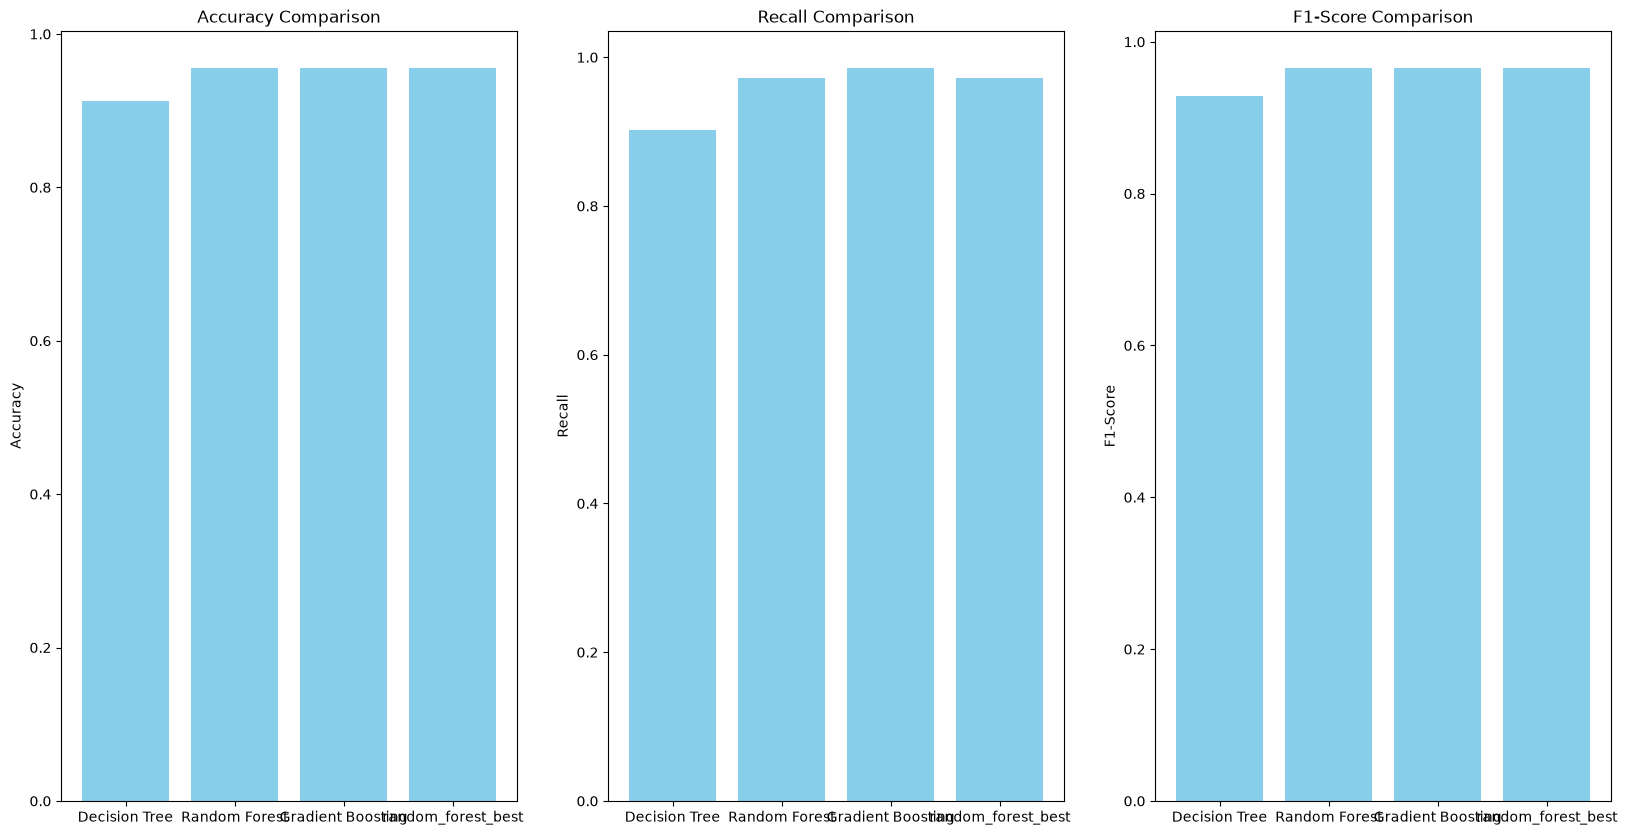

In [81]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1,3 ,figsize=(20, 10))

# barplot for accuracy
axes[0].bar(result['Model'], result['Accuracy'], color='skyblue')
axes[0].set_title('Accuracy Comparison')
axes[0].set_ylabel('Accuracy')

# barplot for recall
axes[1].bar(result['Model'], result['Recall'], color='skyblue')
axes[1].set_title('Recall Comparison')
axes[1].set_ylabel('Recall')

# barplot for F1
axes[2].bar(result['Model'], result['F1-Score'], color='skyblue')
axes[2].set_title('F1-Score Comparison')
axes[2].set_ylabel('F1-Score')


plt.show()

# Plot ROC AUC


AUC : 0.99


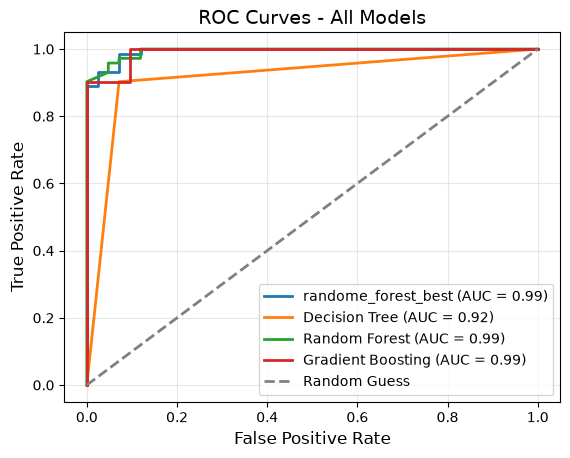

In [ ]:
# calculate ROC and AUC using predict prob, for more accurate classificatoin

# hyperparameter tuned best model
y_pred_proba = best_model.predict_proba(X_test)[:, 1]

roc = roc_curve(y_test,y_pred_proba)
auc_score = auc(roc[0],roc[1])

print(f"AUC :{auc_score: .2f}")
# ploting the cureve
plt.plot(roc[0], roc[1], lw=2, label=f"randome_forest_best (AUC = {auc_score:.2f})")
# finding roc and auc for our previously defined models

for name, model in models.items():
  y_pred_proba = model.predict_proba(X_test)[:, 1]
  roc = roc_curve(y_test, y_pred_proba)
  roc_auc = auc(roc[0], roc[1])

  plt.plot(roc[0], roc[1], lw=2, label=f"{name} (AUC = {roc_auc:.2f})")


plt.plot([0, 1], [0, 1], color="gray", lw=2, linestyle="--", label="Random Guess")

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.title("ROC Curves - All Models", fontsize=14)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show() 

## Final thoughts and observation:

1. Random forest and Gradient boosting seems to be perform the best comparing the other 
2. since the accuracy and other metrics were similar I am taking call on this with recall and choose gradient boost since that is having high recall that maybe super important in medical data 